In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [40]:
# Kaggle: Internet must be enabled for OpenML access.
%pip -q install openml catboost xgboost

import json, re, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report,
    brier_score_loss)
from sklearn.calibration import CalibrationDisplay
from sklearn.utils.class_weight import compute_class_weight
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

RANDOM_STATE = 42
DATASET_ID = 46874  # OpenML version 2; version 1 is a different OpenML record.
TARGET_COLUMN = 'Depression'
FILTER_TO_STUDENTS = True
EXCLUDE_SENSITIVE_MENTAL_HEALTH_INPUTS = True

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.


In [41]:
# Explicit download from OpenML. OpenML caches the ARFF locally in the notebook runtime.
print(f"Downloading OpenML dataset ID {DATASET_ID} ...", flush=True)
dataset = openml.datasets.get_dataset(
    DATASET_ID,
    download_data=True,
    download_qualities=False,
    download_features_meta_data=True
)
print("Download complete:", dataset.name, "| ID:", dataset.dataset_id)
print("Default target recorded by OpenML:", dataset.default_target_attribute)

X_raw, y_raw, categorical_indicator, attribute_names = dataset.get_data(
    dataset_format="dataframe",
    target=TARGET_COLUMN
)
if y_raw is None:
    raise ValueError(
        f"OpenML did not return target {TARGET_COLUMN!r}. "
        "Inspect dataset.default_target_attribute and set TARGET_COLUMN accordingly."
    )
X_raw = X_raw.copy()
y_raw = pd.Series(y_raw, index=X_raw.index, name=TARGET_COLUMN)
df_download = X_raw.copy()
df_download[TARGET_COLUMN] = y_raw

csv_path = "/kaggle/working/student_depression_openml_46874.csv"
df_download.to_csv(csv_path, index=False)
print("Saved CSV copy to:", csv_path)
print("Predictor shape:", X_raw.shape)
print("Target distribution:")
display(y_raw.value_counts(dropna=False).rename("count").to_frame())
display(pd.DataFrame({
    "dtype": X_raw.dtypes.astype(str),
    "missing": X_raw.isna().sum(),
    "unique": X_raw.nunique(dropna=False)
}))
display(X_raw.head())


Download complete: student_depression_dataset | ID: 46874
Default target recorded by OpenML: Depression
Saved CSV copy to: /kaggle/working/student_depression_openml_46874.csv
Predictor shape: (27901, 16)
Target distribution:


,count
Depression,
1,16336
0,11565


,dtype,missing,unique
Gender,object,0,2
Age,uint8,0,34
City,object,0,52
Profession,object,0,14
Academic Pressure,uint8,0,6
Work Pressure,uint8,0,3
CGPA,float64,0,332
Study Satisfaction,uint8,0,6
Job Satisfaction,uint8,0,5
Sleep Duration,object,0,5


,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness
0,Male,33,Visakhapatnam,Student,5,0,8.97,2,0,5-6 hours,Healthy,B.Pharm,Yes,3,1.0,No
1,Female,24,Bangalore,Student,2,0,5.90,5,0,5-6 hours,Moderate,BSc,No,3,2.0,Yes
2,Male,31,Srinagar,Student,3,0,7.03,5,0,Less than 5 hours,Healthy,BA,No,9,1.0,Yes
3,Female,28,Varanasi,Student,3,0,5.59,2,0,7-8 hours,Moderate,BCA,Yes,4,5.0,Yes
4,Female,25,Jaipur,Student,4,0,8.13,3,0,5-6 hours,Moderate,M.Tech,Yes,1,1.0,No


In [42]:
df = X_raw.copy()
df[TARGET_COLUMN] = y_raw
print('Exact duplicate rows:', int(df.duplicated().sum()))

# Keep student records only if the source has a profession column.
profession_col = next((c for c in df.columns if c.strip().lower() == 'profession'), None)
if FILTER_TO_STUDENTS and profession_col:
    vals = df[profession_col].astype(str).str.strip().str.casefold()
    print('Profession values:', sorted(df[profession_col].dropna().astype(str).unique())[:30])
    student_mask = vals.eq('student')
    if student_mask.any():
        df = df.loc[student_mask].copy()
        print('Filtered to student records:', len(df))
    else:
        print('No exact Student category found; leaving rows unchanged. Review profession values.')

# Remove IDs, target copies, and sensitive mental-health predictors.
def norm(s): return re.sub(r'[^a-z0-9]+', ' ', str(s).lower()).strip()
exclude = []
for c in df.columns:
    n = norm(c)
    if c == TARGET_COLUMN:
        continue
    if n in {'id', 'student id', 'row id', 'instance'} or n.endswith(' id'):
        exclude.append(c)
    if EXCLUDE_SENSITIVE_MENTAL_HEALTH_INPUTS and any(term in n for term in [
        'suicidal thought', 'suicide', 'self harm', 'self harm history'
    ]):
        exclude.append(c)
exclude = sorted(set(exclude))
print('Excluded predictors:', exclude)

# Target audit; do not infer clinical truth from this source-defined label.
print('Missing target rows:', int(df[TARGET_COLUMN].isna().sum()))
df = df.dropna(subset=[TARGET_COLUMN]).drop_duplicates().reset_index(drop=True)
display(df[TARGET_COLUMN].value_counts(normalize=True).rename('proportion').to_frame())

# Save a compact dataset profile in Kaggle output.
profile = {
    'openml_dataset_id': DATASET_ID,
    'name': dataset.name,
    'rows_after_filtering': int(len(df)),
    'columns': list(df.columns),
    'excluded_predictors': exclude,
    'target': TARGET_COLUMN,
    'target_counts': {str(k): int(v) for k, v in df[TARGET_COLUMN].value_counts().items()},
    'missing_by_column': {str(k): int(v) for k, v in df.isna().sum().items()}
}
with open('/kaggle/working/openml_dataset_profile.json', 'w') as f:
    json.dump(profile, f, indent=2)
print('Saved /kaggle/working/openml_dataset_profile.json')

Exact duplicate rows: 0
Profession values: ['Architect', 'Chef', 'Civil Engineer', 'Content Writer', 'Digital Marketer', 'Doctor', 'Educational Consultant', 'Entrepreneur', 'Lawyer', 'Manager', 'Pharmacist', 'Student', 'Teacher', 'UX/UI Designer']
Filtered to student records: 27870
Excluded predictors: ['Have you ever had suicidal thoughts ?']
Missing target rows: 0


,proportion
Depression,
1,0.585145
0,0.414855


Saved /kaggle/working/openml_dataset_profile.json


In [43]:
df = X_raw.copy()
df[TARGET_COLUMN] = y_raw
print('Exact duplicate rows:', int(df.duplicated().sum()))

# Keep student records only if the source has a profession column.
profession_col = next((c for c in df.columns if c.strip().lower() == 'profession'), None)
if FILTER_TO_STUDENTS and profession_col:
    vals = df[profession_col].astype(str).str.strip().str.casefold()
    print('Profession values:', sorted(df[profession_col].dropna().astype(str).unique())[:30])
    student_mask = vals.eq('student')
    if student_mask.any():
        df = df.loc[student_mask].copy()
        print('Filtered to student records:', len(df))
    else:
        print('No exact Student category found; leaving rows unchanged. Review profession values.')

# Remove IDs, target copies, and sensitive mental-health predictors.
def norm(s): return re.sub(r'[^a-z0-9]+', ' ', str(s).lower()).strip()
exclude = []
for c in df.columns:
    n = norm(c)
    if c == TARGET_COLUMN:
        continue
    if n in {'id', 'student id', 'row id', 'instance'} or n.endswith(' id'):
        exclude.append(c)
    if EXCLUDE_SENSITIVE_MENTAL_HEALTH_INPUTS and any(term in n for term in [
        'suicidal thought', 'suicide', 'self harm', 'self harm history'
    ]):
        exclude.append(c)
exclude = sorted(set(exclude))
print('Excluded predictors:', exclude)

# Target audit; do not infer clinical truth from this source-defined label.
print('Missing target rows:', int(df[TARGET_COLUMN].isna().sum()))
df = df.dropna(subset=[TARGET_COLUMN]).drop_duplicates().reset_index(drop=True)
display(df[TARGET_COLUMN].value_counts(normalize=True).rename('proportion').to_frame())

# Save a compact dataset profile in Kaggle output.
profile = {
    'openml_dataset_id': DATASET_ID,
    'name': dataset.name,
    'rows_after_filtering': int(len(df)),
    'columns': list(df.columns),
    'excluded_predictors': exclude,
    'target': TARGET_COLUMN,
    'target_counts': {str(k): int(v) for k, v in df[TARGET_COLUMN].value_counts().items()},
    'missing_by_column': {str(k): int(v) for k, v in df.isna().sum().items()}
}
with open('/kaggle/working/openml_dataset_profile.json', 'w') as f:
    json.dump(profile, f, indent=2)
print('Saved /kaggle/working/openml_dataset_profile.json')

Exact duplicate rows: 0
Profession values: ['Architect', 'Chef', 'Civil Engineer', 'Content Writer', 'Digital Marketer', 'Doctor', 'Educational Consultant', 'Entrepreneur', 'Lawyer', 'Manager', 'Pharmacist', 'Student', 'Teacher', 'UX/UI Designer']
Filtered to student records: 27870
Excluded predictors: ['Have you ever had suicidal thoughts ?']
Missing target rows: 0


,proportion
Depression,
1,0.585145
0,0.414855


Saved /kaggle/working/openml_dataset_profile.json


In [44]:
X = df.drop(columns=[TARGET_COLUMN] + exclude, errors='ignore').copy()
y_text = df[TARGET_COLUMN].astype(str).str.strip()
le = LabelEncoder()
y = le.fit_transform(y_text)
print('Target mapping:', dict(zip(le.classes_, le.transform(le.classes_))))
if len(le.classes_) != 2:
    raise ValueError(f'Expected a binary target; found {list(le.classes_)}')

# For consistent positive-class metrics, class 1 should be the positive label.
positive_candidates = [i for i, c in enumerate(le.classes_) if c.casefold() in {'yes', '1', 'true'}]
if positive_candidates and positive_candidates[0] != 1:
    y = 1 - y
    print('Re-encoded target so positive class is 1:', le.classes_[positive_candidates[0]])

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=RANDOM_STATE,
    stratify=y_trainval
)

cat_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
for part in (X_train, X_val, X_test):
    for c in cat_cols:
        part[c] = part[c].fillna('__MISSING__').astype(str)
print('Split sizes:', len(X_train), 'train;', len(X_val), 'validation;', len(X_test), 'test')
print('Categorical:', cat_cols)
print('Numeric:', num_cols)

Target mapping: {'0': np.int64(0), '1': np.int64(1)}
Split sizes: 16722 train; 5574 validation; 5574 test
Categorical: ['Gender', 'City', 'Profession', 'Sleep Duration', 'Dietary Habits', 'Degree', 'Family History of Mental Illness']
Numeric: ['Age', 'Academic Pressure', 'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction', 'Work/Study Hours', 'Financial Stress']


In [46]:
pre = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('ohe', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)
], remainder='drop')

models = {
    'Dummy': DummyClassifier(strategy='prior'),
    'CatBoost': CatBoostClassifier(
        iterations=500, depth=6, learning_rate=0.05, l2_leaf_reg=5,
        loss_function='Logloss', eval_metric='Logloss',
        random_seed=RANDOM_STATE, verbose=False, allow_writing_files=False,
        thread_count=-1, cat_features=cat_cols
    ),
    'XGBoost': Pipeline([
        ('preprocess', pre),
        ('model', XGBClassifier(
            n_estimators=500, max_depth=5, learning_rate=0.05,
            subsample=0.85, colsample_bytree=0.85, reg_lambda=2,
            eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

fitted = {}
rows = []
for name, model in models.items():
    print('Fitting', name, flush=True)
    if name == 'CatBoost':
        model.fit(X_train, y_train)
    else:
        model.fit(X_train, y_train)
    fitted[name] = model
    prob = model.predict_proba(X_val)[:, 1]
    pred = (prob >= 0.5).astype(int)
    rows.append({
        'model': name,
        'accuracy': accuracy_score(y_val, pred),
        'precision_macro': precision_score(y_val, pred, average='macro', zero_division=0),
        'recall_macro': recall_score(y_val, pred, average='macro', zero_division=0),
        'f1_macro': f1_score(y_val, pred, average='macro'),
        'roc_auc': roc_auc_score(y_val, prob),
        'pr_auc': average_precision_score(y_val, prob),
        'brier': brier_score_loss(y_val, prob)
    })

results = pd.DataFrame(rows).sort_values('f1_macro', ascending=False)
display(results)
selected_name = results.iloc[0]['model']
selected_model = fitted[selected_name]
print('Selected using validation macro F1:', selected_name)

Fitting Dummy
Fitting CatBoost
Fitting XGBoost


,model,accuracy,precision_macro,recall_macro,f1_macro,roc_auc,pr_auc,brier
2,XGBoost,0.798170,0.794827,0.785905,0.789246,0.870078,0.897202,0.142603
1,CatBoost,0.797452,0.794470,0.784601,0.788200,0.873088,0.899106,0.140520
0,Dummy,0.585038,0.292519,0.500000,0.369100,0.500000,0.585038,0.242769


Selected using validation macro F1: XGBoost


In [47]:
import numpy as np
import optuna
from optuna.samplers import TPESampler
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import log_loss
from xgboost import XGBClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)

y_tr = np.asarray(y_train)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Preprocess once per fold (fit on the fold's train part only) and cache it,
# so each trial doesn't redo the encoding.
folds = []
for tr_idx, va_idx in cv.split(X_train, y_tr):
    pre_f = clone(pre)
    Xt = pre_f.fit_transform(X_train.iloc[tr_idx])
    Xv = pre_f.transform(X_train.iloc[va_idx])
    folds.append((Xt, y_tr[tr_idx], Xv, y_tr[va_idx]))


def objective(trial):
    params = dict(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 9),
        min_child_weight=trial.suggest_float("min_child_weight", 1, 30, log=True),
        gamma=trial.suggest_float("gamma", 1e-3, 5, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        colsample_bylevel=trial.suggest_float("colsample_bylevel", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-2, 50, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
    )

    losses, best_iters = [], []
    for step, (Xt, yt, Xv, yv) in enumerate(folds):
        m = XGBClassifier(
            **params,
            n_estimators=3000,
            early_stopping_rounds=100,
            eval_metric="logloss",
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
        m.fit(Xt, yt, eval_set=[(Xv, yv)], verbose=False)
        n_trees = m.best_iteration + 1
        p = m.predict_proba(Xv, iteration_range=(0, n_trees))[:, 1]
        losses.append(log_loss(yv, p))
        best_iters.append(n_trees)

        # Prune clearly bad trials early
        trial.report(float(np.mean(losses)), step)
        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr("n_estimators", int(np.median(best_iters)))
    return float(np.mean(losses))


study = optuna.create_study(
    direction="minimize",
    sampler=TPESampler(seed=RANDOM_STATE, multivariate=True),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=15, n_warmup_steps=2),
)

# Seed the search with your current settings as a baseline trial
study.enqueue_trial(dict(
    learning_rate=0.05, max_depth=5, min_child_weight=1.0, gamma=0.001,
    subsample=0.85, colsample_bytree=0.85, colsample_bylevel=1.0,
    reg_lambda=2.0, reg_alpha=0.001,
))

study.optimize(objective, n_trials=150, timeout=60 * 40, show_progress_bar=True)

best = study.best_trial
print("Best CV log loss:", round(best.value, 5))
print("Best params:", best.params)
print("Trees (median best iteration):", best.user_attrs["n_estimators"])


# ---------- Final fit on all of X_train, then ONE look at validation ----------
best_params = best.params
n_trees = int(best.user_attrs["n_estimators"] * 1.1)  # slight bump: final fit uses 25% more data

def make_tuned_xgb(seed):
    return Pipeline([
        ("preprocess", clone(pre)),
        ("model", XGBClassifier(
            **best_params,
            n_estimators=n_trees,
            eval_metric="logloss",
            tree_method="hist",
            random_state=seed,
            n_jobs=-1,
        )),
    ])

# Seed-average to reduce variance
seeds = [RANDOM_STATE + i for i in range(5)]
tuned_models = [make_tuned_xgb(s).fit(X_train, y_train) for s in seeds]
prob = np.mean([m.predict_proba(X_val)[:, 1] for m in tuned_models], axis=0)
pred = (prob >= 0.5).astype(int)

print({
    "accuracy": accuracy_score(y_val, pred),
    "f1_macro": f1_score(y_val, pred, average="macro"),
    "roc_auc": roc_auc_score(y_val, prob),
    "pr_auc": average_precision_score(y_val, prob),
    "brier": brier_score_loss(y_val, prob),
})

  0%|          | 0/150 [00:00<?, ?it/s]

Best CV log loss: 0.4324
Best params: {'learning_rate': 0.01412899174659988, 'max_depth': 2, 'min_child_weight': 17.75040668154238, 'gamma': 0.439173010353502, 'subsample': 0.601952576443968, 'colsample_bytree': 0.4375891879958901, 'colsample_bylevel': 0.5404924929443192, 'reg_lambda': 1.898768564474639, 'reg_alpha': 0.0032127717520493435}
Trees (median best iteration): 1739
{'accuracy': 0.7985288841047722, 'f1_macro': 0.7894902619771935, 'roc_auc': np.float64(0.8737852647588866), 'pr_auc': np.float64(0.8995918073757487), 'brier': np.float64(0.14011878012992093)}


,threshold,macro_f1,yes_precision,yes_recall
46,0.56,0.795653,0.832972,0.825820
45,0.55,0.795419,0.829761,0.831033
50,0.60,0.795088,0.848307,0.799141
43,0.53,0.795079,0.822475,0.843913
44,0.54,0.794293,0.825023,0.837167
49,0.59,0.793914,0.842967,0.804968
48,0.58,0.793101,0.838301,0.810794
42,0.52,0.792929,0.817993,0.847593
47,0.57,0.792703,0.834693,0.816007
52,0.62,0.792426,0.854801,0.783502


Threshold selected on validation: 0.56

Default threshold 0.50 (0.50)
              precision    recall  f1-score   support

          No       0.78      0.71      0.75      2312
         Yes       0.81      0.86      0.83      3262

    accuracy                           0.80      5574
   macro avg       0.79      0.79      0.79      5574
weighted avg       0.80      0.80      0.80      5574

Accuracy: 0.7982
Macro F1: 0.7892

Validation-selected threshold (0.56)
              precision    recall  f1-score   support

          No       0.75      0.75      0.75      2312
         Yes       0.82      0.82      0.82      3262

    accuracy                           0.79      5574
   macro avg       0.78      0.79      0.79      5574
weighted avg       0.79      0.79      0.79      5574

Accuracy: 0.791
Macro F1: 0.7851

Test ROC-AUC: 0.8705
Test PR-AUC: 0.8967
Test Brier score: 0.142


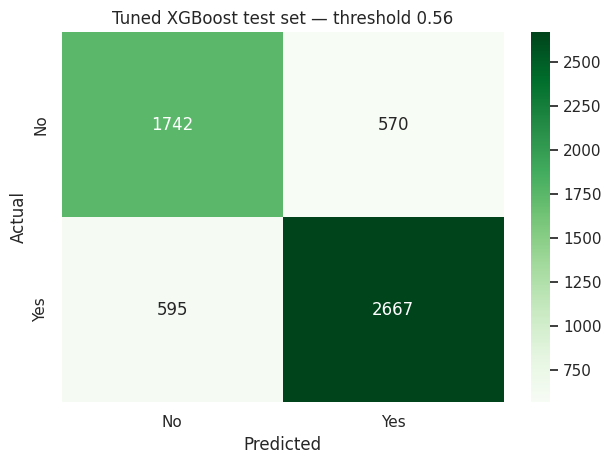

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss,
    classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score
)

# prob is the validation probability from your tuned XGBoost seed ensemble.
# y_val and y_test use 0 = No, 1 = Yes.

threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.01):
    val_pred = (prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "macro_f1": f1_score(y_val, val_pred, average="macro"),
        "yes_precision": precision_score(y_val, val_pred, zero_division=0),
        "yes_recall": recall_score(y_val, val_pred, zero_division=0)
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.sort_values("macro_f1", ascending=False).head(10))

selected_threshold = float(
    threshold_table.loc[threshold_table["macro_f1"].idxmax(), "threshold"]
)
print("Threshold selected on validation:", round(selected_threshold, 2))

# Average the five trained seed models' probabilities on the untouched test set.
test_prob = np.mean(
    [model.predict_proba(X_test)[:, 1] for model in tuned_models],
    axis=0
)

for label, threshold in [
    ("Default threshold 0.50", 0.50),
    ("Validation-selected threshold", selected_threshold)
]:
    test_pred = (test_prob >= threshold).astype(int)
    print(f"\n{label} ({threshold:.2f})")
    print(classification_report(
        y_test, test_pred, target_names=["No", "Yes"], zero_division=0
    ))
    print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
    print("Macro F1:", round(f1_score(y_test, test_pred, average="macro"), 4))

print("\nTest ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))
print("Test PR-AUC:", round(average_precision_score(y_test, test_prob), 4))
print("Test Brier score:", round(brier_score_loss(y_test, test_prob), 4))

# Confusion matrix at the threshold chosen on validation.
test_pred_selected = (test_prob >= selected_threshold).astype(int)
cm = confusion_matrix(y_test, test_pred_selected)

sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Tuned XGBoost test set — threshold {selected_threshold:.2f}")
plt.tight_layout()
plt.show()

In [49]:
import json
import joblib
import numpy as np
import pandas as pd

# Refit using the full development data; keep the held-out test set separate.
X_deploy = pd.concat([X_train, X_val], ignore_index=True)
y_deploy = np.concatenate([np.asarray(y_train), np.asarray(y_val)]).astype(int)

# Ensure categoricals use the same representation expected by the fitted pipeline.
for col in cat_cols:
    if col in X_deploy.columns:
        X_deploy[col] = X_deploy[col].fillna("__MISSING__").astype(str)

deployment_models = []
for seed in seeds:
    print(f"Fitting deployment model with seed {seed}...", flush=True)
    model = make_tuned_xgb(seed)
    model.fit(X_deploy, y_deploy)
    deployment_models.append(model)

deployment_threshold = float(selected_threshold)

deployment_bundle = {
    "models": deployment_models,
    "threshold": deployment_threshold,
    "feature_columns": list(X_train.columns),
    "categorical_columns": list(cat_cols),
    "target_column": "Depression",
    "class_mapping": {"No": 0, "Yes": 1},
    "positive_label": "Yes",
    "openml_dataset_id": 46874,
    "excluded_columns": [
        c for c in ["Have you ever had suicidal thoughts ?"]
        if c not in X_train.columns
    ],
    "random_seeds": list(seeds),
    "xgboost_parameters": dict(best_params),
    "n_estimators": int(n_trees)
}

model_path = "/kaggle/working/mindscope_openml_xgb_ensemble.joblib"
joblib.dump(deployment_bundle, model_path)

metadata_path = "/kaggle/working/mindscope_openml_xgb_ensemble_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump({
        key: value for key, value in deployment_bundle.items()
        if key != "models"
    }, f, indent=2, default=str)

print("Saved model:", model_path)
print("Saved metadata:", metadata_path)
print("Threshold:", round(deployment_threshold, 2))


def predict_mindscope(input_df, bundle=deployment_bundle):
    """Predict the OpenML dataset label; this is not a clinical assessment."""
    if not isinstance(input_df, pd.DataFrame):
        raise TypeError("input_df must be a pandas DataFrame.")

    missing = [
        c for c in bundle["feature_columns"]
        if c not in input_df.columns
    ]
    if missing:
        raise ValueError(f"Missing required feature columns: {missing}")

    X_new = input_df[bundle["feature_columns"]].copy()

    for col in bundle["categorical_columns"]:
        X_new[col] = X_new[col].fillna("__MISSING__").astype(str)

    probabilities = np.mean(
        np.column_stack([
            model.predict_proba(X_new)[:, 1]
            for model in bundle["models"]
        ]),
        axis=1
    )

    labels = np.where(
        probabilities >= bundle["threshold"],
        "Yes",
        "No"
    )

    return pd.DataFrame({
        "dataset_label_estimate": labels,
        "estimated_probability_yes": probabilities,
        "threshold_used": bundle["threshold"]
    })


# Example smoke check using a few validation records:
display(predict_mindscope(X_val.head(5)))

Fitting deployment model with seed 42...
Fitting deployment model with seed 43...
Fitting deployment model with seed 44...
Fitting deployment model with seed 45...
Fitting deployment model with seed 46...
Saved model: /kaggle/working/mindscope_openml_xgb_ensemble.joblib
Saved metadata: /kaggle/working/mindscope_openml_xgb_ensemble_metadata.json
Threshold: 0.56


,dataset_label_estimate,estimated_probability_yes,threshold_used
0,Yes,0.928841,0.56
1,No,0.061007,0.56
2,Yes,0.988011,0.56
3,Yes,0.979506,0.56
4,Yes,0.837228,0.56


Computing SHAP for seed model 1/5...
Computing SHAP for seed model 2/5...
Computing SHAP for seed model 3/5...
Computing SHAP for seed model 4/5...
Computing SHAP for seed model 5/5...
Largest SHAP reconstruction error: 0.264834
Global feature contributions (probability units):


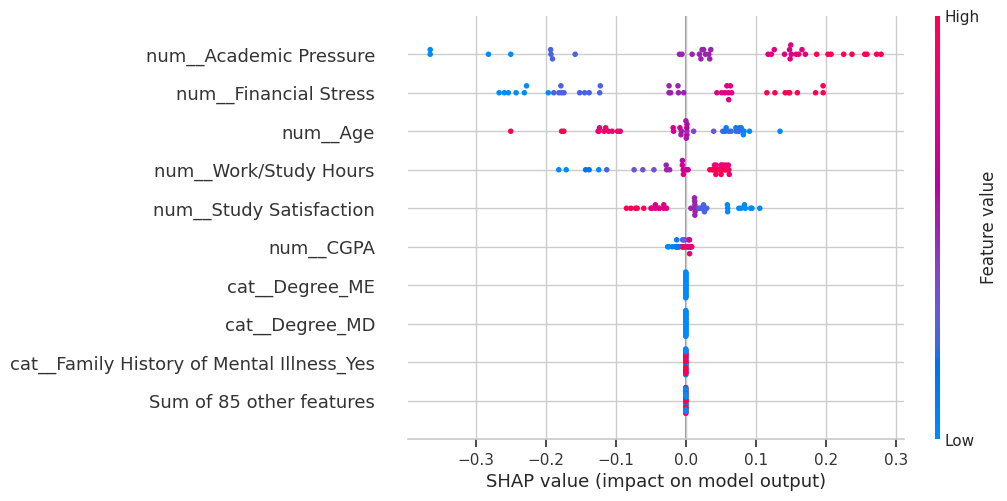

One example:


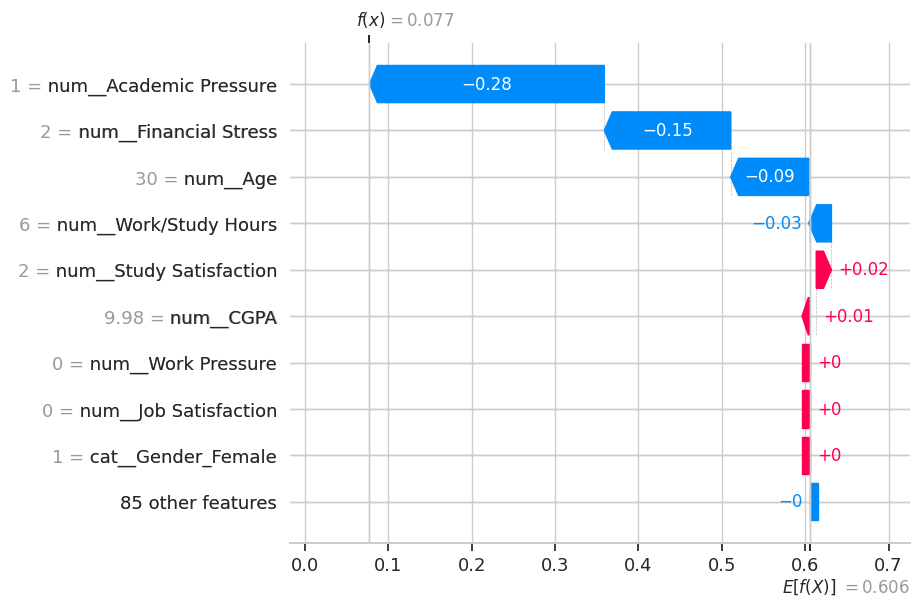

In [51]:
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from scipy import sparse

# Use the five-seed XGBoost ensemble if available; otherwise use the selected
# single XGBoost pipeline.
if "tuned_models" in globals():
    shap_models = tuned_models
elif "deployment_bundle" in globals():
    shap_models = deployment_bundle["models"]
    if isinstance(shap_models, dict):
        shap_models = list(shap_models.values())
elif "selected_model" in globals():
    shap_models = [selected_model]
else:
    raise NameError("Could not find tuned_models, deployment_bundle, or selected_model.")

if not shap_models:
    raise ValueError("No fitted model found to explain.")

# These pipelines should have preprocessing and model steps.
first_model = shap_models[0]
if not hasattr(first_model, "named_steps") or "preprocess" not in first_model.named_steps:
    raise ValueError(
        "Expected a fitted XGBoost pipeline with a 'preprocess' step. "
        "Use the fitted XGBoost pipeline, not raw XGBoost estimator."
    )

preprocessor = first_model.named_steps["preprocess"]
feature_columns = list(X_train.columns)

background_raw = X_train[feature_columns].sample(
    min(50, len(X_train)), random_state=42
).copy()
explain_raw = X_test[feature_columns].sample(
    min(40, len(X_test)), random_state=43
).copy()

# Transform categorical strings into numeric one-hot features.
background = preprocessor.transform(background_raw)
explain_data = preprocessor.transform(explain_raw)

if sparse.issparse(background):
    background = background.toarray()
if sparse.issparse(explain_data):
    explain_data = explain_data.toarray()

background = np.asarray(background, dtype=float)
explain_data = np.asarray(explain_data, dtype=float)
transformed_names = preprocessor.get_feature_names_out()

# Explain each seed model in probability space, then average SHAP values.
all_shap_values = []
all_base_values = []

for i, pipeline in enumerate(shap_models, start=1):
    print(f"Computing SHAP for seed model {i}/{len(shap_models)}...", flush=True)

    tree_model = pipeline.named_steps["model"]
    explainer = shap.TreeExplainer(
        tree_model,
        data=background,
        feature_perturbation="interventional",
        model_output="probability"
    )

    values = explainer.shap_values(explain_data, check_additivity=True)

    # Handle SHAP versions that return class-specific arrays.
    if isinstance(values, list):
        values = values[1]
    values = np.asarray(values)
    if values.ndim == 3:
        values = values[:, :, 1]

    base = np.asarray(explainer.expected_value)
    if base.ndim > 0 and base.size > 1:
        base = base.reshape(-1)[1]
    else:
        base = float(base.reshape(-1)[0])

    all_shap_values.append(values)
    all_base_values.append(base)

mean_values = np.mean(np.stack(all_shap_values), axis=0)
mean_base = float(np.mean(all_base_values))

explanation = shap.Explanation(
    values=mean_values,
    base_values=np.full(len(explain_data), mean_base),
    data=explain_data,
    feature_names=list(transformed_names)
)

# Check SHAP reconstruction against the ensemble's average probability.
ensemble_probability = np.mean(
    np.column_stack([
        model.predict_proba(explain_raw)[:, 1]
        for model in shap_models
    ]),
    axis=1
)
reconstructed_probability = mean_base + mean_values.sum(axis=1)

print(
    "Largest SHAP reconstruction error:",
    round(float(np.max(np.abs(
        ensemble_probability - reconstructed_probability
    ))), 6)
)

print("Global feature contributions (probability units):")
shap.plots.beeswarm(explanation)

print("One example:")
shap.plots.waterfall(explanation[0])

Threshold: 0.56
Test Brier score: 0.142


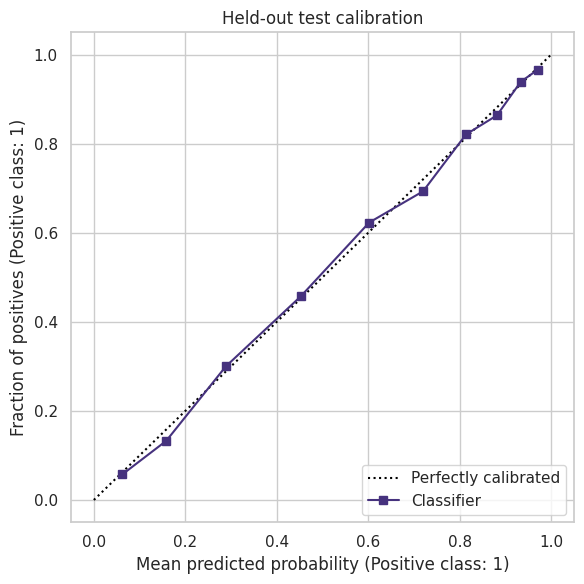

Stratified bootstrap intervals:


,metric,estimate,95% CI lower,95% CI upper
0,ROC-AUC,0.8705,0.8606,0.8793
1,PR-AUC,0.8967,0.8879,0.9051
2,Brier,0.1420,0.1367,0.1476
3,Macro F1,0.7851,0.7734,0.7949
4,Yes precision,0.8239,0.8127,0.8336
5,Yes recall,0.8176,0.8041,0.8299


Subgroup metrics on held-out test data:


,feature,group,n,actual_yes_rate,yes_recall,recall_95%_CI,yes_precision,precision_95%_CI,no_specificity
0,Gender,Female,2456,0.585,0.831,0.81–0.85,0.822,0.80–0.84,0.746
1,Gender,Male,3118,0.586,0.807,0.79–0.82,0.826,0.81–0.84,0.759
2,Financial Stress,1.0,994,0.319,0.549,0.49–0.60,0.719,0.66–0.77,0.900
3,Financial Stress,2.0,1014,0.436,0.631,0.59–0.67,0.762,0.72–0.80,0.848
4,Financial Stress,3.0,1045,0.596,0.787,0.75–0.82,0.807,0.77–0.84,0.723
5,Financial Stress,4.0,1148,0.686,0.882,0.86–0.90,0.840,0.81–0.86,0.634
6,Financial Stress,5.0,1373,0.796,0.942,0.93–0.95,0.861,0.84–0.88,0.407
7,Family History of Mental Illness,No,2830,0.568,0.789,0.77–0.81,0.816,0.80–0.83,0.766
8,Family History of Mental Illness,Yes,2744,0.603,0.845,0.83–0.86,0.831,0.81–0.85,0.739


In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)

# Get test-set probabilities from an existing variable or fitted model.
if "test_prob" in globals():
    p_eval = np.asarray(test_prob).reshape(-1)
elif "tuned_models" in globals():
    p_eval = np.mean(
        np.column_stack([
            model.predict_proba(X_test)[:, 1]
            for model in tuned_models
        ]),
        axis=1
    )
elif "selected_model" in globals():
    p_eval = selected_model.predict_proba(X_test)[:, 1]
else:
    raise NameError("Could not find test_prob, tuned_models, or selected_model.")

y_eval = np.asarray(y_test).astype(int)
threshold = float(globals().get("selected_threshold", 0.5))

if len(p_eval) != len(y_eval) or len(X_test) != len(y_eval):
    raise ValueError("X_test, y_test, and test probabilities must have matching rows.")

pred_eval = (p_eval >= threshold).astype(int)

# Calibration plot and Brier score.
print("Threshold:", round(threshold, 3))
print("Test Brier score:", round(brier_score_loss(y_eval, p_eval), 4))

fig, ax = plt.subplots(figsize=(6, 6))
CalibrationDisplay.from_predictions(
    y_eval,
    p_eval,
    n_bins=10,
    strategy="quantile",
    ax=ax
)
ax.set_title("Held-out test calibration")
plt.tight_layout()
plt.show()

# Stratified bootstrap confidence intervals preserve the test-set class counts.
rng = np.random.default_rng(42)
positive_idx = np.flatnonzero(y_eval == 1)
negative_idx = np.flatnonzero(y_eval == 0)

def get_metrics(indices):
    y_sample = y_eval[indices]
    p_sample = p_eval[indices]
    pred_sample = (p_sample >= threshold).astype(int)

    return {
        "ROC-AUC": roc_auc_score(y_sample, p_sample),
        "PR-AUC": average_precision_score(y_sample, p_sample),
        "Brier": brier_score_loss(y_sample, p_sample),
        "Macro F1": f1_score(y_sample, pred_sample, average="macro"),
        "Yes precision": precision_score(y_sample, pred_sample, zero_division=0),
        "Yes recall": recall_score(y_sample, pred_sample, zero_division=0)
    }

point = get_metrics(np.arange(len(y_eval)))
bootstrap_values = {metric: [] for metric in point}

for _ in range(1000):
    sample_pos = rng.choice(positive_idx, size=len(positive_idx), replace=True)
    sample_neg = rng.choice(negative_idx, size=len(negative_idx), replace=True)
    indices = np.concatenate([sample_pos, sample_neg])

    for metric, value in get_metrics(indices).items():
        bootstrap_values[metric].append(value)

ci_table = pd.DataFrame([
    {
        "metric": metric,
        "estimate": point[metric],
        "95% CI lower": np.percentile(values, 2.5),
        "95% CI upper": np.percentile(values, 97.5)
    }
    for metric, values in bootstrap_values.items()
])

print("Stratified bootstrap intervals:")
display(ci_table.round(4))

# Subgroup checks; groups smaller than 50 are skipped.
def wilson_interval(successes, total, z=1.96):
    if total == 0:
        return np.nan, np.nan
    rate = successes / total
    denom = 1 + z**2 / total
    center = (rate + z**2 / (2 * total)) / denom
    margin = (
        z * np.sqrt(rate * (1 - rate) / total + z**2 / (4 * total**2))
        / denom
    )
    return center - margin, center + margin

group_columns = [
    "Gender",
    "Financial Stress",
    "Family History of Mental Illness"
]

group_rows = []
minimum_group_size = 50

for column in group_columns:
    if column not in X_test.columns:
        print(f"Skipping {column}: not present in X_test.")
        continue

    values = X_test[column].fillna("<Missing>").astype(str).reset_index(drop=True)

    for group in sorted(values.unique()):
        mask = (values == group).to_numpy()
        n = int(mask.sum())

        if n < minimum_group_size:
            print(f"Skipping {column}={group}: only {n} test rows.")
            continue

        actual = y_eval[mask]
        predicted = pred_eval[mask]

        tp = int(((actual == 1) & (predicted == 1)).sum())
        fp = int(((actual == 0) & (predicted == 1)).sum())
        fn = int(((actual == 1) & (predicted == 0)).sum())
        tn = int(((actual == 0) & (predicted == 0)).sum())

        recall = tp / (tp + fn) if tp + fn else np.nan
        precision = tp / (tp + fp) if tp + fp else np.nan
        recall_lo, recall_hi = wilson_interval(tp, tp + fn)
        precision_lo, precision_hi = wilson_interval(tp, tp + fp)

        group_rows.append({
            "feature": column,
            "group": group,
            "n": n,
            "actual_yes_rate": actual.mean(),
            "yes_recall": recall,
            "recall_95%_CI": f"{recall_lo:.2f}–{recall_hi:.2f}",
            "yes_precision": precision,
            "precision_95%_CI": f"{precision_lo:.2f}–{precision_hi:.2f}",
            "no_specificity": tn / (tn + fp) if tn + fp else np.nan
        })

print("Subgroup metrics on held-out test data:")
display(pd.DataFrame(group_rows).round(3))

In [53]:
import json
import joblib
import numpy as np
import pandas as pd

# Refit on all development rows after model selection.
if "X_trainval" in globals() and "y_trainval" in globals():
    X_deploy = X_trainval.copy()
    y_deploy = np.asarray(y_trainval).astype(int)
else:
    X_deploy = pd.concat([X_train, X_val], ignore_index=True)
    y_deploy = np.concatenate([
        np.asarray(y_train),
        np.asarray(y_val)
    ]).astype(int)

X_deploy = X_deploy.reset_index(drop=True)

# Use the five seeds from your tuned XGBoost run.
deployment_seeds = [RANDOM_STATE + i for i in range(5)]
deployment_models = []

for seed in deployment_seeds:
    print(f"Fitting deployment model with seed {seed}...", flush=True)
    model = make_tuned_xgb(seed)
    model.fit(X_deploy, y_deploy)
    deployment_models.append(model)

# selected_threshold should be 0.56 from your validation threshold search.
deployment_threshold = float(selected_threshold)

bundle = {
    "models": deployment_models,
    "threshold": deployment_threshold,
    "feature_columns": list(X_train.columns),
    "categorical_columns": list(cat_cols),
    "target_column": "Depression",
    "class_mapping": {"No": 0, "Yes": 1},
    "positive_label": "Yes",
    "openml_dataset_id": 46874,
    "random_seeds": deployment_seeds,
    "xgboost_parameters": dict(best_params),
    "n_estimators": int(n_trees)
}

model_path = "/kaggle/working/mindscope_openml_xgb_ensemble.joblib"
metadata_path = "/kaggle/working/mindscope_openml_xgb_ensemble_metadata.json"

joblib.dump(bundle, model_path)

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(
        {key: value for key, value in bundle.items() if key != "models"},
        f,
        indent=2,
        default=str
    )

print("Saved model:", model_path)
print("Saved metadata:", metadata_path)
print("Threshold:", round(deployment_threshold, 2))


def predict_mindscope(input_df, model_bundle=bundle):
    """Predict the dataset label. This is not a clinical assessment."""
    if not isinstance(input_df, pd.DataFrame):
        raise TypeError("input_df must be a pandas DataFrame.")

    missing = [
        col for col in model_bundle["feature_columns"]
        if col not in input_df.columns
    ]
    if missing:
        raise ValueError(f"Missing required features: {missing}")

    X_new = input_df[model_bundle["feature_columns"]].copy()

    for col in model_bundle["categorical_columns"]:
        X_new[col] = X_new[col].fillna("__MISSING__").astype(str)

    prob_yes = np.mean(
        np.column_stack([
            model.predict_proba(X_new)[:, 1]
            for model in model_bundle["models"]
        ]),
        axis=1
    )

    return pd.DataFrame({
        "dataset_label_estimate": np.where(
            prob_yes >= model_bundle["threshold"], "Yes", "No"
        ),
        "estimated_probability_yes": prob_yes,
        "threshold_used": model_bundle["threshold"]
    })


# Optional wiring check; these rows are training data after the refit,
# so do not treat the predictions as evaluation results.
display(predict_mindscope(X_val.head(5)))

Fitting deployment model with seed 42...
Fitting deployment model with seed 43...
Fitting deployment model with seed 44...
Fitting deployment model with seed 45...
Fitting deployment model with seed 46...
Saved model: /kaggle/working/mindscope_openml_xgb_ensemble.joblib
Saved metadata: /kaggle/working/mindscope_openml_xgb_ensemble_metadata.json
Threshold: 0.56


,dataset_label_estimate,estimated_probability_yes,threshold_used
0,Yes,0.927191,0.56
1,No,0.059064,0.56
2,Yes,0.988026,0.56
3,Yes,0.979713,0.56
4,Yes,0.839578,0.56


In [54]:
import os
import zipfile
from IPython.display import FileLink, display

files_to_zip = [
    "/kaggle/working/mindscope_openml_xgb_ensemble.joblib",
    "/kaggle/working/mindscope_openml_xgb_ensemble_metadata.json"
]

missing = [path for path in files_to_zip if not os.path.exists(path)]
if missing:
    raise FileNotFoundError(f"Files not found: {missing}")

zip_path = "/kaggle/working/mindscope_openml_model_bundle.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in files_to_zip:
        zf.write(path, arcname=os.path.basename(path))

display(FileLink(zip_path))

/kaggle/working/mindscope_openml_model_bundle.zip

In [55]:
!ls -lh /kaggle/working/mindscope_openml_xgb_ensemble*

-rw-r--r-- 1 root root 8.2M Nov 23 00:37 /kaggle/working/mindscope_openml_xgb_ensemble.joblib
-rw-r--r-- 1 root root 1.2K Nov 23 00:37 /kaggle/working/mindscope_openml_xgb_ensemble_metadata.json


In [56]:
import xgboost
print(xgboost.__version__)

3.4.1


In [57]:
import joblib
model = joblib.load("/kaggle/working/mindscope_openml_xgb_ensemble.joblib")
print(type(model))

<class 'dict'>


In [58]:
for key, value in model.items():
    try:
        size = len(value)
    except TypeError:
        size = ""
    print(key, type(value), size)

models <class 'list'> 5
threshold <class 'float'> 
feature_columns <class 'list'> 15
categorical_columns <class 'list'> 7
target_column <class 'str'> 10
class_mapping <class 'dict'> 2
positive_label <class 'str'> 3
openml_dataset_id <class 'int'> 
random_seeds <class 'list'> 5
xgboost_parameters <class 'dict'> 9
n_estimators <class 'int'> 


In [59]:
for i, member in enumerate(model["models"]):
    print(f"\nMember {i}: {type(member)}")
    print("Steps:", list(member.named_steps) if hasattr(member, "named_steps") else "no pipeline")
    print("Classes:", getattr(member, "classes_", "not exposed"))


Member 0: <class 'sklearn.pipeline.Pipeline'>
Steps: ['preprocess', 'model']
Classes: [0 1]

Member 1: <class 'sklearn.pipeline.Pipeline'>
Steps: ['preprocess', 'model']
Classes: [0 1]

Member 2: <class 'sklearn.pipeline.Pipeline'>
Steps: ['preprocess', 'model']
Classes: [0 1]

Member 3: <class 'sklearn.pipeline.Pipeline'>
Steps: ['preprocess', 'model']
Classes: [0 1]

Member 4: <class 'sklearn.pipeline.Pipeline'>
Steps: ['preprocess', 'model']
Classes: [0 1]


In [60]:
from pathlib import Path
import hashlib

p = Path("/kaggle/working/mindscope_openml_xgb_ensemble.joblib")
print("bytes:", p.stat().st_size)
print("sha256:", hashlib.sha256(p.read_bytes()).hexdigest())

bytes: 8595584
sha256: fcdd6a8ed30710a6cb5b13bb9e78ae16bd536b3483459db0a8d8162aebfda82e


In [61]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED`
import json
import joblib
import numpy as np
import pandas as pd
import sklearn
import xgboost

out = Path("/kaggle/working/mindscope_portable")
out.mkdir(exist_ok=True)

preprocessors = []
boosters = []

for i, pipe in enumerate(model["models"]):
    prep_file = f"preprocess_{i}.joblib"
    booster_file = f"booster_{i}.json"

    joblib.dump(pipe.named_steps["preprocess"], out / prep_file, compress=3)
    pipe.named_steps["model"].get_booster().save_model(str(out / booster_file))

    preprocessors.append(prep_file)
    boosters.append(booster_file)

manifest = {
    "feature_columns": model["feature_columns"],
    "categorical_columns": model["categorical_columns"],
    "threshold": float(model["threshold"]),
    "class_mapping": model["class_mapping"],
    "positive_label": model["positive_label"],
    "openml_dataset_id": model["openml_dataset_id"],
    "aggregation": "mean of the five members' Yes probabilities",
    "xgboost_version": xgboost.__version__,
    "scikit_learn_version": sklearn.__version__,
    "preprocessors": preprocessors,
    "boosters": boosters,
}
(out / "manifest.json").write_text(json.dumps(manifest, indent=2))

zip_path = Path("/kaggle/working/mindscope_portable.zip")
with ZipFile(zip_path, "w", ZIP_DEFLATED) as z:
    for file in out.iterdir():
        z.write(file, arcname=file.name)

print("Created:", zip_path)
print("Bytes:", zip_path.stat().st_size)

Created: /kaggle/working/mindscope_portable.zip
Bytes: 1177789


In [62]:
import numpy as np
import pandas as pd

sample = pd.read_csv(
    "/kaggle/working/student_depression_openml_46874.csv"
)[model["feature_columns"]].head(10)

member_probs = np.column_stack([
    member.predict_proba(sample)[:, 1]
    for member in model["models"]
])

print(np.round(member_probs.mean(axis=1), 6).tolist())

[0.27652499079704285, 0.13792599737644196, 0.14135700464248657, 0.7749750018119812, 0.31199800968170166, 0.08668100088834763, 0.09542199969291687, 0.10367099940776825, 0.749068021774292, 0.47008898854255676]
